# Machine learning: apprendimento supervisionato e non supervisionato
**Progetto Big Data for Official Statistics – notebook 04**

Il programma del corso (Parte II) presenta i metodi di machine learning nel contesto della statistica ufficiale: apprendimento **supervisionato** (regressione logistica, random forest) e **non supervisionato** (clustering). Questo notebook li applica ai nostri dati.

**A. Supervisionato.** Possiamo prevedere chi fa sport tra gli 11 e i 24 anni? Un modello più flessibile (random forest, gradient boosting) fa meglio della regressione logistica del notebook 02?

**B. Non supervisionato.** Esistono gruppi di regioni simili per pratica sportiva, condizioni sociali e impianti (dato OpenStreetMap)? Il risultato è una **tipologia** di regioni (cap. 1 del corso: classificazione, tipologie e tassonomie).

In [1]:
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapefile
from matplotlib.patches import Polygon as PoligonoMpl
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, brier_score_loss, roc_auc_score, silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)  # vedi notebook 02

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG, RES = ROOT / "figures", ROOT / "results"
dati = pd.read_parquet(ROOT / "data" / "processed" / "avq_sport_2014_2024.parquet")

In [2]:
# Stile grafici (palette di riferimento, modalità chiara)
SUPERFICIE, TESTO, TESTO_2, GRIGLIA = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLU, ARANCIO, ACQUA, GIALLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "text.color": TESTO, "axes.labelcolor": TESTO_2, "xtick.color": TESTO_2, "ytick.color": TESTO_2,
    "axes.edgecolor": GRIGLIA, "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRIGLIA, "grid.linewidth": 0.8, "lines.linewidth": 2, "legend.frameon": False,
})

def fonte(ax, testo, y=-0.16):
    ax.annotate(testo, xy=(0, y), xycoords="axes fraction", fontsize=8, color=TESTO_2)

## A. Apprendimento supervisionato: prevedere chi fa sport (11-24 anni)

**Impostazione**
- Variabile da prevedere: `pratica_sport` (sì / no).
- Predittori: sesso, classe di età, regione, titolo di studio più alto in famiglia, risorse economiche della famiglia, numero di componenti, anno.
- **Divisione temporale**: i modelli imparano sugli anni 2014-2022 e vengono valutati sul 2023-2024. È lo scenario realistico per la statistica ufficiale: un modello costruito sul passato deve funzionare sulle nuove edizioni dell'indagine.
- I pesi campionari entrano sia nell'addestramento sia nelle misure di valutazione, perché i risultati devono valere per la popolazione e non per il campione.

**Modelli confrontati**
- *baseline*: prevede per tutti la stessa probabilità (la quota media di praticanti);
- **regressione logistica**: lineare e interpretabile, senza interazioni;
- **random forest**: molti alberi di decisione, coglie da solo interazioni e non linearità;
- **gradient boosting**: alberi costruiti in sequenza, ognuno corregge gli errori dei precedenti.

**Misure**: AUC (capacità di distinguere chi fa sport da chi no: 0,5 = a caso, 1 = perfetto), Brier score (errore medio delle probabilità, più basso è meglio), accuratezza con soglia 0,5.

In [3]:
CATEGORICHE = ["sesso", "eta_classe", "regione", "titolo_max_famiglia", "risorse_economiche"]
NUMERICHE = ["n_componenti", "anno"]
g = dati[dati.eta_classe.isin(["11-13", "14-15", "16-17", "18-19", "20-24"])].dropna(
    subset=CATEGORICHE + NUMERICHE + ["pratica_sport"]).copy()
for c in CATEGORICHE:
    g[c] = g[c].astype(str)
g["n_componenti"] = g.n_componenti.clip(upper=6).astype(float)  # 6 = "6 o più"
X, y, w = g[CATEGORICHE + NUMERICHE], g.pratica_sport.astype(int), g.peso / g.peso.mean()
train, test = g.anno <= 2022, g.anno >= 2023
print(f"addestramento 2014-2022: {train.sum():,} giovani | test 2023-2024: {test.sum():,} giovani")

def codifica():
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICHE)],
                             remainder="passthrough")

MODELLI = {
    "Baseline": make_pipeline(codifica(), DummyClassifier(strategy="prior")),
    "Regressione logistica": make_pipeline(codifica(), StandardScaler(), LogisticRegression(max_iter=3000)),
    "Random forest": make_pipeline(codifica(), RandomForestClassifier(
        n_estimators=400, min_samples_leaf=30, max_features="sqrt", n_jobs=-1, random_state=0)),
    "Gradient boosting": make_pipeline(codifica(), HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.05, random_state=0)),
}
risultati, previsioni = [], {}
for nome, modello in MODELLI.items():
    passo_finale = modello.steps[-1][0]
    modello.fit(X[train], y[train], **{f"{passo_finale}__sample_weight": w[train]})
    p = modello.predict_proba(X[test])[:, 1]
    previsioni[nome] = p
    risultati.append({"modello": nome,
                      "AUC": roc_auc_score(y[test], p, sample_weight=w[test]),
                      "Brier": brier_score_loss(y[test], p, sample_weight=w[test]),
                      "Accuratezza": accuracy_score(y[test], p > 0.5, sample_weight=w[test])})
valutazione = pd.DataFrame(risultati).set_index("modello")
valutazione.to_csv(RES / "ml_confronto_modelli.csv")
valutazione.round(3)

addestramento 2014-2022: 51,212 giovani | test 2023-2024: 10,948 giovani


,AUC,Brier,Accuratezza
modello,,,
Baseline,0.500,0.237,0.614
Regressione logistica,0.671,0.218,0.648
Random forest,0.670,0.218,0.648
Gradient boosting,0.669,0.218,0.651


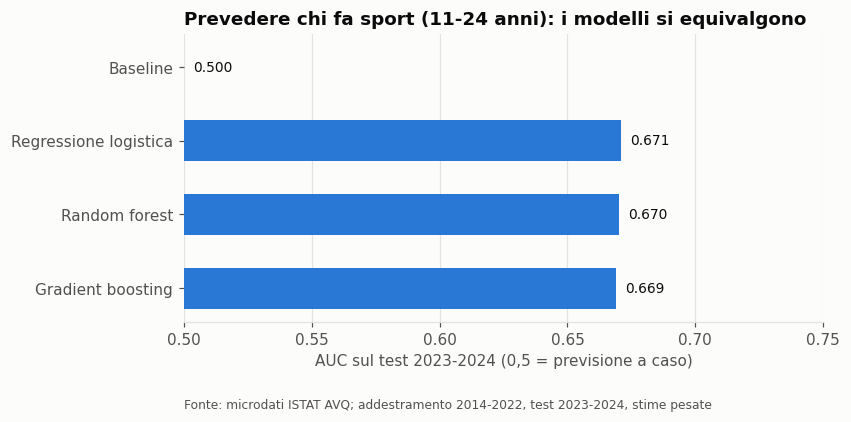

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
yy = np.arange(len(valutazione))[::-1]
colori = [GRIGLIA if n == "Baseline" else BLU for n in valutazione.index]
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.barh(yy, valutazione.AUC - 0.5, left=0.5, height=0.55, color=colori)
for yi, v in zip(yy, valutazione.AUC):
    ax.annotate(f"{v:.3f}", (v, yi), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9)
ax.set_yticks(yy, valutazione.index)
ax.set_xlim(0.5, 0.75)
ax.set_xlabel("AUC sul test 2023-2024 (0,5 = previsione a caso)")
ax.set_title("Prevedere chi fa sport (11-24 anni): i modelli si equivalgono")
fonte(ax, "Fonte: microdati ISTAT AVQ; addestramento 2014-2022, test 2023-2024, stime pesate", y=-0.3)
fig.savefig(FIG / "15_ml_confronto_modelli.png")
plt.show()

### Quali variabili contano?
**Importanza per permutazione** sul random forest: si mescolano a caso i valori di una variabile nel test e si misura quanto peggiora l'AUC. Più peggiora, più il modello dipende da quella variabile. Funziona con qualsiasi modello, anche quelli "a scatola nera".

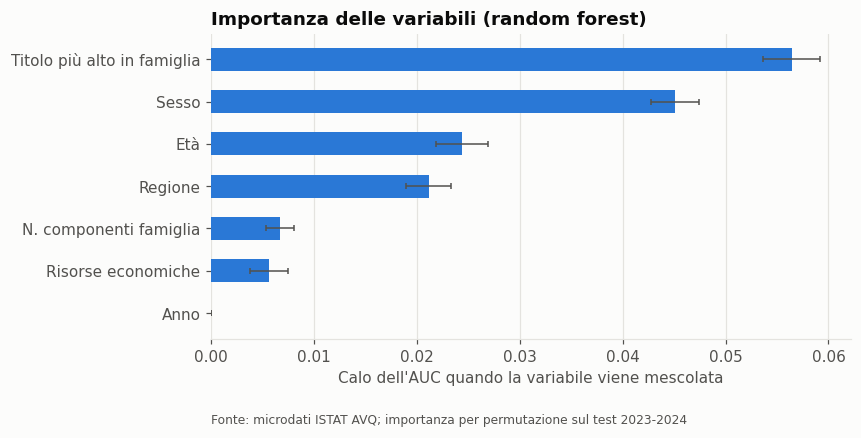

,calo_AUC,dev_std
titolo_max_famiglia,0.0564,0.0028
sesso,0.0451,0.0023
eta_classe,0.0244,0.0025
regione,0.0211,0.0022
n_componenti,0.0067,0.0014
risorse_economiche,0.0056,0.0018
anno,0.0000,0.0000


In [5]:
NOMI = {"titolo_max_famiglia": "Titolo più alto in famiglia", "sesso": "Sesso", "eta_classe": "Età",
        "regione": "Regione", "n_componenti": "N. componenti famiglia",
        "risorse_economiche": "Risorse economiche", "anno": "Anno"}
imp = permutation_importance(MODELLI["Random forest"], X[test], y[test], scoring="roc_auc", n_repeats=10,
                             random_state=0, sample_weight=w[test], n_jobs=-1)
importanza = pd.DataFrame({"calo_AUC": imp.importances_mean, "dev_std": imp.importances_std},
                          index=X.columns).sort_values("calo_AUC")
importanza.to_csv(RES / "ml_importanza_variabili.csv")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
yy = np.arange(len(importanza))
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.barh(yy, importanza.calo_AUC, xerr=importanza.dev_std, height=0.55, color=BLU,
        error_kw=dict(ecolor=TESTO_2, elinewidth=1, capsize=2))
ax.set_yticks(yy, [NOMI[i] for i in importanza.index])
ax.set_xlabel("Calo dell'AUC quando la variabile viene mescolata")
ax.set_title("Importanza delle variabili (random forest)")
fonte(ax, "Fonte: microdati ISTAT AVQ; importanza per permutazione sul test 2023-2024", y=-0.28)
fig.savefig(FIG / "16_ml_importanza_variabili.png")
plt.show()
importanza.sort_values("calo_AUC", ascending=False).round(4)

### Uso statistico: stime regionali costruite dal modello
Nella statistica ufficiale un modello serve spesso a produrre **stime aggregate**, non previsioni individuali. Confrontiamo, per il test 2023-2024, la quota di praticanti per regione stimata direttamente dall'indagine con quella ricostruita dal modello (media pesata delle probabilità previste).

In [6]:
t = g[test].assign(p_logit=previsioni["Regressione logistica"], p_rf=previsioni["Random forest"],
                   y=y[test], w=w[test])
stime_reg = t.groupby("regione").apply(lambda d: pd.Series({
    "diretta": 100 * np.average(d.y, weights=d.w),
    "logistica": 100 * np.average(d.p_logit, weights=d.w),
    "random_forest": 100 * np.average(d.p_rf, weights=d.w),
    "n": len(d)}), include_groups=False).sort_values("diretta")
for m in ["logistica", "random_forest"]:
    print(f"{m}: scarto medio assoluto dalla stima diretta = {np.mean(np.abs(stime_reg[m] - stime_reg.diretta)):.1f} punti")
stime_reg.to_csv(RES / "ml_stime_regionali.csv")
stime_reg.round(1)

logistica: scarto medio assoluto dalla stima diretta = 3.1 punti
random_forest: scarto medio assoluto dalla stima diretta = 3.3 punti


,diretta,logistica,random_forest,n
regione,,,,
Calabria,45.2,52.5,55.8,428.0
Campania,48.4,44.3,48.6,913.0
Sicilia,51.5,48.6,52.1,711.0
Basilicata,54.1,49.1,57.5,290.0
Puglia,56.7,56.0,58.1,649.0
Friuli-Venezia Giulia,57.7,61.5,60.0,366.0
Sardegna,58.9,56.7,58.3,357.0
Molise,59.4,55.8,60.6,268.0
Umbria,60.0,63.0,62.4,314.0


## B. Apprendimento non supervisionato: una tipologia delle regioni

Per ogni regione costruiamo 7 indicatori (microdati AVQ 2022-2024 e OpenStreetMap):

| Indicatore | Fonte |
|---|---|
| pratica sportiva, 3 anni e più (%) | AVQ |
| pratica sportiva, 11-24 anni (%) | AVQ |
| divario di genere nella pratica (punti, maschi − femmine) | AVQ |
| sedentari: né sport né attività fisica (%) | AVQ |
| persone in famiglie con almeno un laureato (%) | AVQ |
| persone in famiglie con risorse scarse o insufficienti (%) | AVQ |
| impianti sportivi ogni 10.000 abitanti, al 1° gennaio 2024 | OSM (ohsome) |

Gli indicatori sono **standardizzati** (media 0, deviazione standard 1), altrimenti quelli con valori più grandi peserebbero di più. Il **clustering gerarchico con il metodo di Ward** unisce passo dopo passo le regioni più simili; il numero di gruppi si sceglie guardando il dendrogramma e l'indice di silhouette.

In [7]:
recenti = dati[(dati.anno >= 2022) & dati.regione.notna()]
tre_piu = recenti[recenti.eta_classe != "0-2"]

def quota(d, condizione):
    validi = condizione.notna()
    return 100 * np.average(condizione[validi].astype(float), weights=d.peso[validi])

indicatori = pd.DataFrame({
    "pratica_sport": tre_piu.groupby("regione", observed=True).apply(lambda d: quota(d, d.pratica_sport), include_groups=False),
    "pratica_giovani": tre_piu[tre_piu.eta_classe.isin(["11-13", "14-15", "16-17", "18-19", "20-24"])]
        .groupby("regione", observed=True).apply(lambda d: quota(d, d.pratica_sport), include_groups=False),
    "divario_genere": tre_piu.groupby("regione", observed=True).apply(
        lambda d: quota(d[d.sesso == "Maschio"], d[d.sesso == "Maschio"].pratica_sport)
                  - quota(d[d.sesso == "Femmina"], d[d.sesso == "Femmina"].pratica_sport), include_groups=False),
    "sedentari": tre_piu.groupby("regione", observed=True).apply(
        lambda d: quota(d, (d.livello_attivita == "Sedentario").where(d.livello_attivita.notna())), include_groups=False),
    "famiglie_laureato": recenti.groupby("regione", observed=True).apply(
        lambda d: quota(d, (d.titolo_max_famiglia == "Laurea e post-laurea").where(d.titolo_max_famiglia.notna())),
        include_groups=False),
    "risorse_scarse": recenti.groupby("regione", observed=True).apply(
        lambda d: quota(d, d.risorse_economiche.isin(["Scarse", "Assolutamente insufficienti"])
                        .where(d.risorse_economiche.notna())), include_groups=False),
})
storico = pd.read_csv(ROOT / "data" / "processed" / "ohsome_impianti_storico.csv")
impianti_2024 = storico[storico.anno == 2024].groupby("regione").n_elementi.sum()
popolazione = dati[(dati.anno == 2024) & dati.regione.notna()].groupby("regione", observed=True).peso.sum()
indicatori["impianti_10mila"] = impianti_2024 / popolazione * 10_000
indicatori.index = indicatori.index.astype(str)
indicatori.to_csv(RES / "cluster_indicatori_regioni.csv")
indicatori.round(1)

,pratica_sport,pratica_giovani,divario_genere,sedentari,famiglie_laureato,risorse_scarse,impianti_10mila
regione,,,,,,,
Piemonte,38.9,64.1,10.1,29.7,25.8,35.4,19.4
Valle d'Aosta,47.2,69.7,10.1,23.4,27.5,32.5,33.0
Lombardia,42.9,63.0,11.6,25.3,31.0,30.7,17.9
Trentino-Alto Adige,55.1,71.6,11.3,15.1,28.9,24.4,35.3
Veneto,43.7,65.1,10.7,23.9,28.7,32.7,21.7
Friuli-Venezia Giulia,39.4,61.0,10.5,23.2,29.2,32.0,27.0
Liguria,37.1,65.1,13.8,30.4,30.8,29.4,18.6
Emilia-Romagna,41.8,67.4,12.0,27.1,30.4,32.4,17.0
Toscana,39.0,63.7,9.8,29.5,29.5,31.7,19.3


Silhouette per numero di gruppi: {2: np.float64(0.413), 3: np.float64(0.311), 4: np.float64(0.31), 5: np.float64(0.283), 6: np.float64(0.259)}


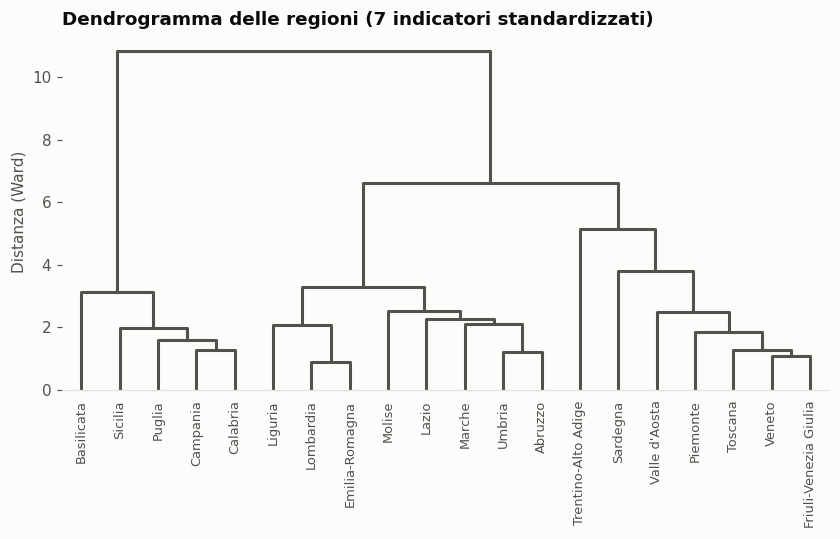

In [8]:
Z = (indicatori - indicatori.mean()) / indicatori.std()
albero = linkage(Z, method="ward")
silhouette = {k: silhouette_score(Z, fcluster(albero, k, "maxclust")) for k in range(2, 7)}
print("Silhouette per numero di gruppi:", {k: round(v, 3) for k, v in silhouette.items()})

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.grid(False)
dendrogram(albero, labels=Z.index.tolist(), leaf_rotation=90, leaf_font_size=8.5, ax=ax,
           color_threshold=0, above_threshold_color=TESTO_2)
ax.set_ylabel("Distanza (Ward)")
ax.set_title("Dendrogramma delle regioni (7 indicatori standardizzati)")
fig.savefig(FIG / "17_cluster_dendrogramma.png")
plt.show()

In [9]:
# K = 2 ha la silhouette più alta, ma separa solo il Mezzogiorno dal resto (lo sapevamo già).
# K = 3 ha una silhouette quasi uguale a K = 4 e aggiunge una distinzione interpretabile nel Centro-Nord.
K = 3
gruppi = pd.Series(fcluster(albero, K, "maxclust"), index=Z.index)
profili = indicatori.groupby(gruppi).mean()
# nomi dai profili: il gruppo con meno pratica, poi tra gli altri due quello con più impianti
basso = profili.pratica_sport.idxmin()
altri = profili.drop(basso)
NOMI_GRUPPI = {altri.impianti_10mila.idxmax(): "Molti impianti per abitante",
               altri.impianti_10mila.idxmin(): "Famiglie più istruite, meno impianti",
               basso: "Bassa pratica (Mezzogiorno)"}
gruppi = gruppi.map(NOMI_GRUPPI)
profili = indicatori.groupby(gruppi).mean().loc[list(NOMI_GRUPPI.values())]
profili["n_regioni"] = gruppi.value_counts()
profili["regioni"] = gruppi.groupby(gruppi).apply(lambda s: ", ".join(sorted(s.index)))
profili.to_csv(RES / "cluster_profili.csv")
profili.round(1)

,pratica_sport,pratica_giovani,divario_genere,sedentari,famiglie_laureato,risorse_scarse,impianti_10mila,n_regioni,regioni
Molti impianti per abitante,42.6,64.9,10.0,25.7,27.8,31.8,27.3,7,"Friuli-Venezia Giulia, Piemonte, Sardegna, Tos..."
"Famiglie più istruite, meno impianti",38.1,63.4,11.9,32.0,33.2,32.2,19.1,8,"Abruzzo, Emilia-Romagna, Lazio, Liguria, Lomba..."
Bassa pratica (Mezzogiorno),25.2,50.1,9.9,52.4,26.3,35.0,12.7,5,"Basilicata, Calabria, Campania, Puglia, Sicilia"


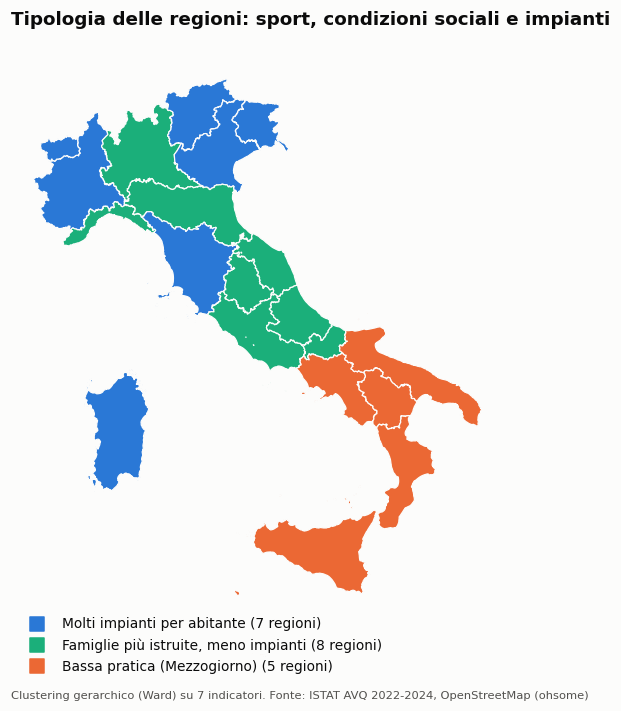

In [10]:
COLORI_GRUPPI = dict(zip(NOMI_GRUPPI.values(), [BLU, ACQUA, ARANCIO]))
lettore = shapefile.Reader(str(ROOT / "data" / "raw" / "confini_istat" / "Reg01012025_g" / "Reg01012025_g_WGS84"))

fig, ax = plt.subplots(figsize=(6.5, 7.5))
ax.set_aspect("equal")
ax.axis("off")
for record, forma in zip(lettore.records(), lettore.shapes()):
    nome = record["DEN_REG"]
    colore = COLORI_GRUPPI[gruppi[nome]]
    parti = list(forma.parts) + [len(forma.points)]
    for a, b in zip(parti[:-1], parti[1:]):
        ax.add_patch(PoligonoMpl(forma.points[a:b], closed=True, facecolor=colore, edgecolor=SUPERFICIE,
                                 linewidth=0.8))
ax.autoscale_view()
for gruppo, colore in COLORI_GRUPPI.items():
    ax.scatter([], [], color=colore, s=80, marker="s", label=f"{gruppo} ({(gruppi == gruppo).sum()} regioni)")
ax.legend(loc="lower left", fontsize=9)
ax.set_title("Tipologia delle regioni: sport, condizioni sociali e impianti")
ax.annotate("Clustering gerarchico (Ward) su 7 indicatori. Fonte: ISTAT AVQ 2022-2024, OpenStreetMap (ohsome)",
            xy=(0, -0.02), xycoords="axes fraction", fontsize=7.5, color=TESTO_2)
fig.savefig(FIG / "18_cluster_mappa.png")
plt.show()

## Lettura dei risultati

**A. Supervisionato**
- **I modelli si equivalgono:** regressione logistica, random forest e gradient boosting hanno la stessa AUC sul 2023-2024 (0,67) e lo stesso Brier score (0,218). L'accuratezza sale dal 61% della baseline al 65%.
- **La pratica sportiva è difficile da prevedere a livello individuale** con le informazioni dell'indagine: contano molto fattori che non osserviamo (gusti, amici, tempo libero, offerta locale). Questo vale per tutti i modelli: un algoritmo più complesso non crea informazione che i dati non contengono.
- **Per la statistica ufficiale è un buon argomento per il modello interpretabile:** a parità di prestazioni, la regressione logistica si spiega, si controlla e si comunica meglio di una scatola nera.
- **Le variabili più importanti** (permutazione sul random forest) sono le stesse del notebook 02: titolo di studio della famiglia, sesso, età e regione. L'anno non conta, perché i modelli sono valutati su anni nuovi e non c'è un trend netto tra i giovani.
- **Stime regionali dal modello:** ricostruiscono quelle dirette con uno scarto medio di circa 3 punti. Gli scarti maggiori sono in regioni piccole o particolari (Calabria, Emilia-Romagna): il modello "appiattisce" le regioni verso la media dei profili sociali. È il limite tipico delle stime basate su modelli, da conoscere prima di usarle per piccole aree.
- **Attenzione all'uso:** un modello che prevede meno sport per le ragazze e per il Sud riproduce le disuguaglianze presenti nei dati. Usarlo per decidere *dove* investire o *a chi* proporre attività rischierebbe di consolidarle invece di ridurle (cap. 1 del corso, "quando gli algoritmi codificano i pregiudizi").

**B. Non supervisionato**
- **La struttura principale è la divisione Nord-Sud:** con 2 gruppi la silhouette è massima (0,41) e separa il Mezzogiorno dal resto.
- **Con 3 gruppi emerge una distinzione nel Centro-Nord:**
  - *Molti impianti per abitante*: Friuli-Venezia Giulia, Piemonte, Sardegna, Toscana, Trentino-Alto Adige, Valle d'Aosta, Veneto (27 impianti ogni 10.000 abitanti, pochi sedentari);
  - *Famiglie più istruite, meno impianti*: Abruzzo, Emilia-Romagna, Lazio, Liguria, Lombardia, Marche, Molise, Umbria (33% delle persone in famiglie con un laureato, 19 impianti);
  - *Bassa pratica (Mezzogiorno)*: Basilicata, Calabria, Campania, Puglia, Sicilia (pratica 25%, metà della popolazione sedentaria, 13 impianti).
- **La Sardegna è nel primo gruppo per via del dato OSM:** il caricamento in blocco del 2015 (notebook 03) la fa sembrare ricca di impianti. È un esempio concreto di come un difetto di qualità della fonte big data si trasmette alla classificazione finale.